# 04 · Train the U-Net risk-map model
**Burn In Only What Matters** · ECE 8803-AI4 · Fall 2026

CRISP-DM phases covered: **Modeling** and **Evaluation on Lots 1–4**.

**Model (slide 6).** A per-wafer image-to-image U-Net:
* input: one wafer as a 16-channel image on the 193×115 KAI grid:
  * one-hot outside / pass / fail (channels 0–2), the channels the encoder was pre-trained on,
  * parameter_1–5 as z-scores (channels 3–7),
  * derived features: abs z (channels 8–12) and distance to the nearest fail, clipped at 20 dies (channel 13),
  * x and y coordinates (channels 14–15);
* output: one risk score per die.

Normalisation statistics are fitted on the training lots of each fold.

**Architecture.** Encoder blocks of 32→64→128→128 channels, two 3×3 conv + BatchNorm + ReLU layers per
block, with max-pool between blocks (Module 3 blocks, doubled). The decoder uses bilinear upsampling with
skip connections, and the input is also skipped straight to a 1×1 head so the model can use die-level
parametric clues directly.

**Loss.** Binary cross-entropy on **passing dies only**, with `pos_weight` = 10 for the ~1.2% positives.

**Threshold.** Swept, not learned. Every result is a full burn-in-vs-recall curve.

**Validation.** Leave-one-lot-out over Lots 1–4. Training uses flip augmentation; the coordinate
channels are kept fixed under flips. The best epoch is chosen by validation average precision, and the
final model trains on all 4 lots for the median best epoch.

**Ablation (slide 7).** The same model with no WM811K pre-training.

## 0 · Setup

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
COLAB_ROOT = "/content/drive/MyDrive/BurnIn_Project"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(COLAB_ROOT)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "burnin").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from burnin import Paths
from burnin.config import TRAIN_LOTS
from burnin.data import load_visible, attach_hidden, channel_names
from burnin.metrics import compare, screening_curve, recall_ceiling, bootstrap_ci
from burnin.cv import UNET_DEFAULTS, lolo_unet, fit_final_unet
from burnin.train import get_device
from burnin.plots import show_failmap, show_latent, show_risk, plot_curves

SIM = os.environ.get("BURNIN_SIM", "sim_dev")
P = Paths(ROOT, sim=SIM)
print("dataset:", P.sim_dir)
DEVICE = get_device()
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(CPU: expect ~20x slower)")
SEED = 0
CFG = dict(UNET_DEFAULTS)
print("U-Net config:", CFG)
print("input channels:", channel_names(CFG["derived"]))

dataset: C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\cache\sim_full
device: cuda NVIDIA RTX A2000 8GB Laptop GPU
U-Net config: {'derived': True, 'epochs': None, 'lr': 0.002, 'pos_weight': 10.0, 'dropout': 0.2, 'weight_decay': 0.01, 'batch': 4, 'eval_every': None}
input channels: ['outside', 'pass', 'fail', 'z_parameter_1', 'z_parameter_2', 'z_parameter_3', 'z_parameter_4', 'z_parameter_5', 'abs_z_parameter_1', 'abs_z_parameter_2', 'abs_z_parameter_3', 'abs_z_parameter_4', 'abs_z_parameter_5', 'dist_to_fail', 'x_coord', 'y_coord']


## 1 · Data (Lots 1–4) and the pre-trained encoder from notebook 03

In [2]:
ws = attach_hidden(load_visible(P.visible), P.hidden, analysis=True).lots(TRAIN_LOTS)
ENC = torch.load(P.models / "encoder_wm811k.pt", map_location="cpu")
CEILING = recall_ceiling(ws)
print(f"{len(ws)} wafers, recall ceiling {CEILING:.1%}")

800 wafers, recall ceiling 85.6%


## 2 · Leave-one-lot-out CV: pre-trained encoder

In [3]:
oof_pre, ep_pre, hist_pre = lolo_unet(ws, encoder_state=ENC, seed=SEED, **CFG)
print("best epoch per fold:", ep_pre)

--- fold: validate on Lot_1 (600 train wafers, 20 epochs)


epoch   1  loss 0.7252  val AP 0.051  val recall@10% 0.320  (5s)


epoch   2  loss 0.4462  val AP 0.068  val recall@10% 0.454  (9s)


epoch   3  loss 0.3253  val AP 0.214  val recall@10% 0.561  (13s)


epoch   4  loss 0.3087  val AP 0.229  val recall@10% 0.568  (18s)


epoch   5  loss 0.3058  val AP 0.241  val recall@10% 0.575  (22s)


... (75 outputs left out)

epoch  18  loss 0.2981  val AP 0.277  val recall@10% 0.595  (87s)


epoch  19  loss 0.2983  val AP 0.277  val recall@10% 0.593  (92s)


epoch  20  loss 0.2982  val AP 0.277  val recall@10% 0.594  (98s)


best epoch per fold: {'Lot_1': 19, 'Lot_2': 19, 'Lot_3': 17, 'Lot_4': 20}


## 3 · Leave-one-lot-out CV: no pre-training (ablation)

In [4]:
oof_scr, ep_scr, hist_scr = lolo_unet(ws, encoder_state=None, seed=SEED, **CFG)
print("best epoch per fold:", ep_scr)

--- fold: validate on Lot_1 (600 train wafers, 20 epochs)


epoch   1  loss 0.7291  val AP 0.052  val recall@10% 0.306  (5s)


epoch   2  loss 0.4498  val AP 0.073  val recall@10% 0.477  (10s)


epoch   3  loss 0.3287  val AP 0.208  val recall@10% 0.556  (15s)


epoch   4  loss 0.3095  val AP 0.226  val recall@10% 0.569  (20s)


epoch   5  loss 0.3060  val AP 0.241  val recall@10% 0.575  (25s)


... (75 outputs left out)

epoch  18  loss 0.2980  val AP 0.277  val recall@10% 0.595  (86s)


epoch  19  loss 0.2983  val AP 0.276  val recall@10% 0.593  (91s)


epoch  20  loss 0.2981  val AP 0.277  val recall@10% 0.595  (95s)


best epoch per fold: {'Lot_1': 19, 'Lot_2': 19, 'Lot_3': 17, 'Lot_4': 20}


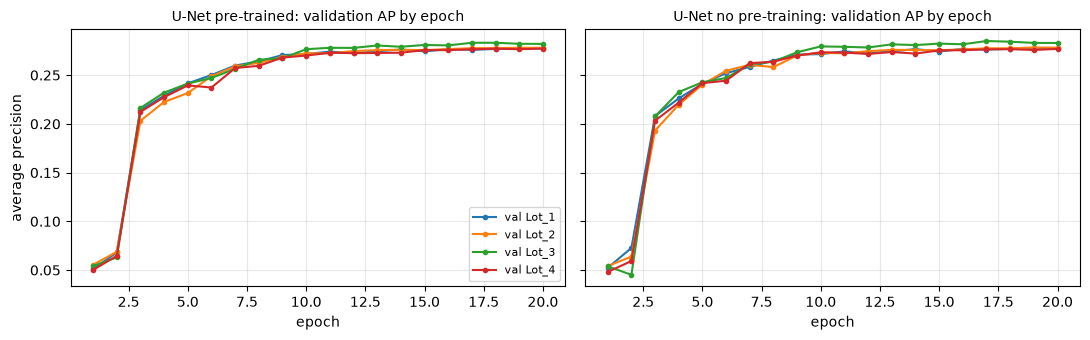

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, (name, H) in zip(ax, [("pre-trained", hist_pre), ("no pre-training", hist_scr)]):
    for lot, h in H.items():
        h = pd.DataFrame(h).dropna(subset=["val_ap"])
        a.plot(h["epoch"], h["val_ap"], marker=".", label=f"val {lot}")
    a.set_title(f"U-Net {name}: validation AP by epoch", fontsize=10)
    a.set_xlabel("epoch"); a.grid(alpha=0.3)
ax[0].set_ylabel("average precision"); ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4 · Comparison with the baselines (all out-of-fold on Lots 1–4)
The baseline scores come from notebook 02 (`results/sim_dev/oof_baselines.npz`).

In [6]:
b = np.load(P.results / "oof_baselines.npz")
assert np.array_equal(b["wafer"], ws.wafer)
scores = {k: b[k] for k in b.files if k != "wafer"}
scores["U-Net (no pre-training)"] = oof_scr
scores["U-Net (pre-trained)"] = oof_pre
table, curves = compare(scores, ws)
table.round(3)

,recall@5%burn,recall@10%burn,recall@20%burn,burn%@80%recall,burn%@90%recall,AUC,AP,DPPM@10%burn
method,,,,,,,,
Random,0.049,0.100,0.199,0.800,0.901,0.500,0.014,12844.612
Distance to fail,0.165,0.330,0.551,0.516,0.745,0.721,0.036,9591.158
Wafer-level fallback,0.162,0.287,0.460,0.569,0.751,0.684,0.032,10202.473
Neighbor z-score,0.355,0.450,0.567,0.547,0.754,0.736,0.155,7884.658
Hotelling T2 (PCA),0.392,0.480,0.588,0.532,0.744,0.748,0.216,7465.973
Feature GBM,0.475,0.593,0.754,0.247,0.479,0.846,0.279,5849.091
U-Net (no pre-training),0.473,0.593,0.755,0.246,0.474,0.846,0.278,5845.356
U-Net (pre-trained),0.474,0.594,0.755,0.245,0.474,0.846,0.278,5837.980


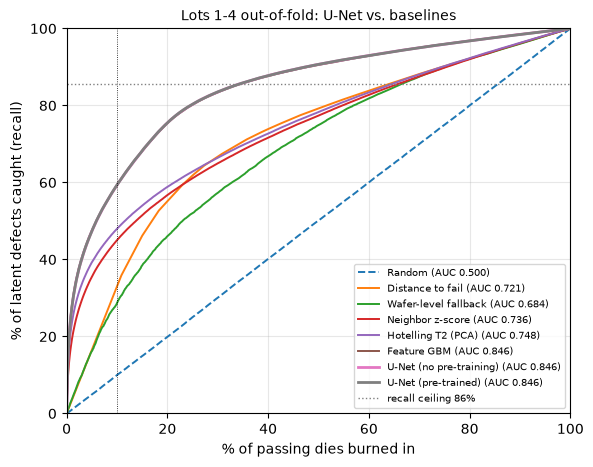

In [7]:
plot_curves(curves, ceiling=CEILING, title="Lots 1-4 out-of-fold: U-Net vs. baselines")
plt.show()

Wafer-bootstrap 95% CI for recall at 10% burn-in (resampling wafers, not dies, because dies on one
wafer are correlated):

In [8]:
ci = {k: bootstrap_ci(scores[k], ws, n_boot=300) for k in ["Feature GBM", "U-Net (no pre-training)", "U-Net (pre-trained)", "Distance to fail"]}
pd.DataFrame(ci, index=["2.5%", "97.5%"]).T.assign(point=[table.loc[k, "recall@10%burn"] for k in ci]).round(3)

,2.5%,97.5%,point
Feature GBM,0.588,0.598,0.593
U-Net (no pre-training),0.588,0.598,0.593
U-Net (pre-trained),0.589,0.598,0.594
Distance to fail,0.317,0.341,0.330


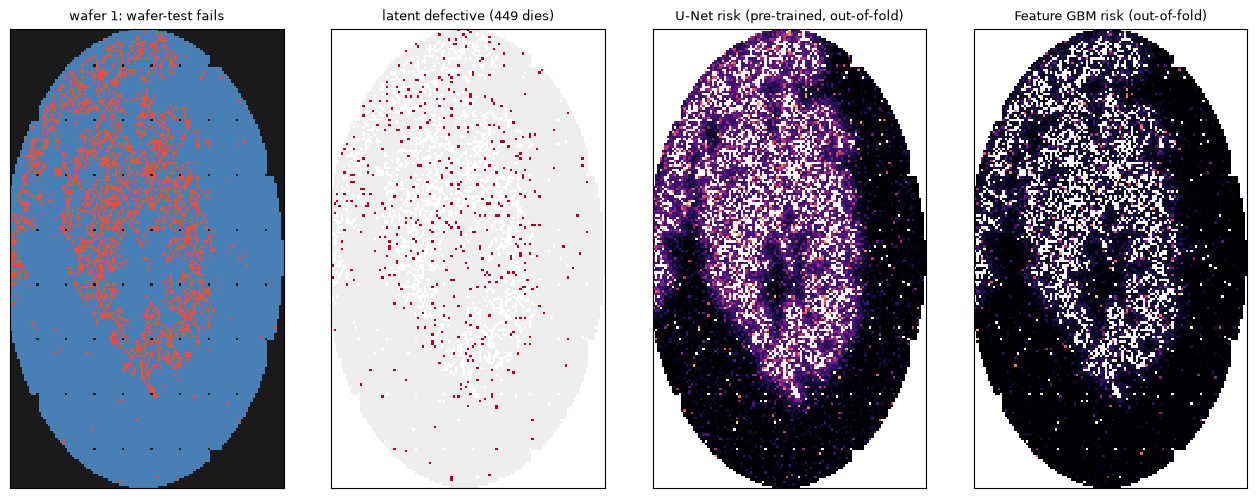

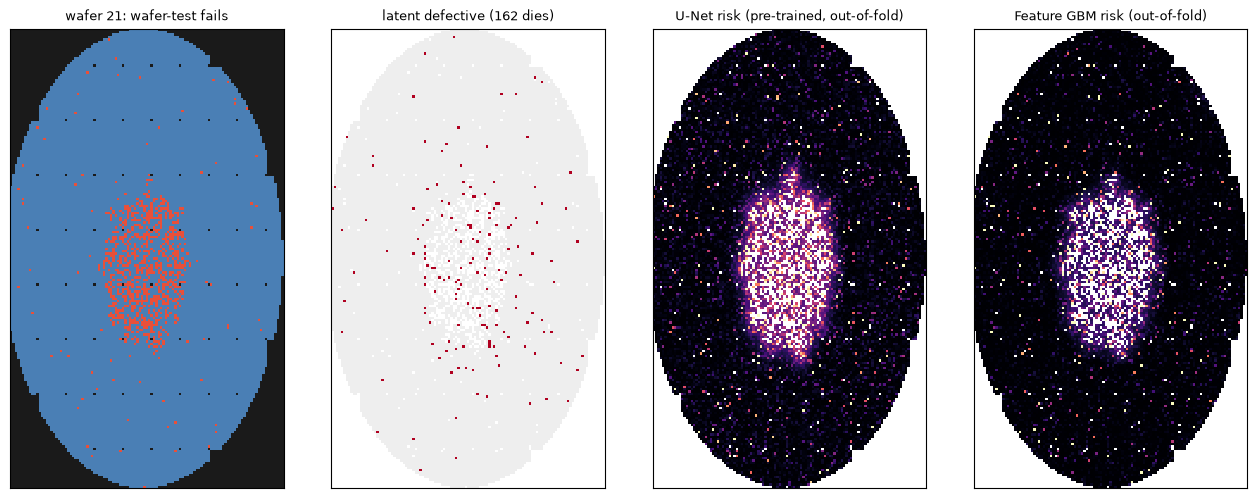

In [9]:
for i in [0, 20]:
    fig, ax = plt.subplots(1, 4, figsize=(13, 5))
    show_failmap(ax[0], ws, i)
    show_latent(ax[1], ws, i)
    show_risk(ax[2], ws, i, oof_pre, "U-Net risk (pre-trained, out-of-fold)")
    show_risk(ax[3], ws, i, scores["Feature GBM"], "Feature GBM risk (out-of-fold)")
    plt.tight_layout()
    plt.show()

## 5 · Train the final models on all of Lots 1–4
Epoch count = median of the per-fold best epochs. No validation lot is used here; Lot 5 stays untouched
until notebook 05.

In [10]:
final = {}
for name, enc, eps in [("unet_pretrained", ENC, ep_pre), ("unet_scratch", None, ep_scr)]:
    E = int(np.median(list(eps.values())))
    net, norm, derived, _ = fit_final_unet(ws, E, encoder_state=enc, seed=SEED, **{k: v for k, v in CFG.items() if k != "epochs"})
    torch.save({"state": net.state_dict(), "mean": norm.mean.tolist(), "std": norm.std.tolist(), "derived": derived,
                "in_ch": len(channel_names(derived)), "epochs": E, "cfg": CFG}, P.models / f"{name}_{P.sim}.pt")
    final[name] = E
    print(f"saved {name}: {E} epochs")
np.savez_compressed(P.results / "oof_unet.npz", wafer=ws.wafer, pretrained=oof_pre, scratch=oof_scr)
table.to_csv(P.results / "oof_all_table.csv")
(P.results / "unet_cv.json").write_text(json.dumps({"best_epochs_pretrained": ep_pre, "best_epochs_scratch": ep_scr,
                                                    "final_epochs": final, "cfg": CFG}, indent=2))

saved unet_pretrained: 19 epochs


saved unet_scratch: 19 epochs


461